# Proyecto Adquisición de Datos - Institución Universitaria ITM (2022-1 a 2023-2)
**Impacto de las variables meteorológicas en la asistencia presencial y el rendimiento en Cálculo Diferencial**

Este cuaderno reproduce exactamente la arquitectura ELT, exponiendo paso a paso la auditoría de nulos, outliers, duplicados, cruces y métricas estadísticas.

In [47]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

BASE_DIR = Path(".")
RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
INTEGRATED_DIR = BASE_DIR / "data" / "integrated"
FIGURES_DIR = BASE_DIR / "outputs" / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
INTEGRATED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Capa Bronze (`data/raw/`): Extracción e Inspección Inicial
Carga de las 3 fuentes originales sin modificación para auditar su volumen inicial.

In [48]:
df_rfid_raw = pd.read_parquet(RAW_DIR / "sensor_rfid_aula_raw.parquet")

with open(RAW_DIR / "open_meteo_sedes_raw.json", "r", encoding="utf-8") as f:
    weather_json = json.load(f)

w_frames = []
for sede, payload in weather_json["sedes"].items():
    df_sede = pd.DataFrame(payload["hourly"])
    df_sede["campus"] = sede
    df_sede["latitude"] = payload["latitude"]
    df_sede["longitude"] = payload["longitude"]
    w_frames.append(df_sede)
df_weather_raw = pd.concat(w_frames, ignore_index=True)

excel_files = sorted(RAW_DIR.glob("Procesado_*.xlsx"))
acad_frames = []
for xfile in excel_files:
    periodo = xfile.stem.replace("Procesado_", "")
    df_sem = pd.read_excel(xfile)
    df_sem["periodo"] = periodo
    acad_frames.append(df_sem)
df_acad_raw = pd.concat(acad_frames, ignore_index=True)

print("RFID raw:", df_rfid_raw.shape)
print("Clima raw:", df_weather_raw.shape)
print("Académico raw:", df_acad_raw.shape)

RFID raw: (69469, 13)
Clima raw: (70080, 7)
Académico raw: (2045, 17)


## 2. Capa Silver (`data/processed/`): Auditoría de Calidad, Nulos y Outliers

### 2.1 Sensor RFID: Outliers de RSSI, Duplicados y Nulos de Asistencia
- Rango físico válido RSSI UHF: $[-90, -20]$ dBm (valores como $+18.5$ dBm son outliers corruptos).
- Deduplicación por `id_evento` conservando el registro con mayor puntaje de completitud.
- Imputación de `estado_asistencia` nulo usando el umbral de $15$ minutos de retraso.

Picos corruptos RSSI (outliers): 206
Valores únicos de outliers RSSI: [18.5]
Eventos RFID duplicados: 551
Estados de asistencia nulos: 413


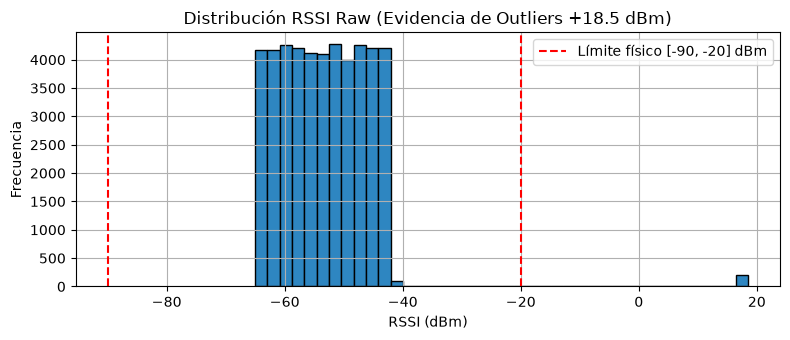

In [49]:
df_rfid = df_rfid_raw.copy()

rssi_out_bounds = df_rfid["rssi_dbm"].notna() & ((df_rfid["rssi_dbm"] < -90.0) | (df_rfid["rssi_dbm"] > -20.0))
duplicados_rfid = df_rfid["id_evento"].duplicated().sum()
nulos_estado_antes = df_rfid["estado_asistencia"].isna().sum()

print("Picos corruptos RSSI (outliers):", rssi_out_bounds.sum())
print("Valores únicos de outliers RSSI:", df_rfid.loc[rssi_out_bounds, "rssi_dbm"].unique())
print("Eventos RFID duplicados:", duplicados_rfid)
print("Estados de asistencia nulos:", nulos_estado_antes)

fig, ax = plt.subplots(figsize=(8, 3.5))
df_rfid_raw["rssi_dbm"].dropna().hist(bins=40, ax=ax, color="#2E86C1", edgecolor="black")
ax.axvline(-90, color="red", linestyle="--", label="Límite físico [-90, -20] dBm")
ax.axvline(-20, color="red", linestyle="--")
ax.set_title("Distribución RSSI Raw (Evidencia de Outliers +18.5 dBm)")
ax.set_xlabel("RSSI (dBm)")
ax.set_ylabel("Frecuencia")
ax.legend()
plt.tight_layout()
plt.show()

In [50]:
df_rfid.loc[rssi_out_bounds, "rssi_dbm"] = np.nan

df_rfid["_q_score"] = df_rfid["estado_asistencia"].notna().astype(int) * 2 + df_rfid["rssi_dbm"].notna().astype(int)
df_rfid = (
    df_rfid.sort_values(["id_evento", "_q_score"], ascending=[True, False])
    .drop_duplicates(subset=["id_evento"], keep="first")
    .drop(columns=["_q_score"])
    .reset_index(drop=True)
)

sched_dt = pd.to_datetime(df_rfid["fecha"] + " " + df_rfid["bloque_hora"])
delay_min = (df_rfid["timestamp_entrada"] - sched_dt).dt.total_seconds() / 60.0
df_rfid["retraso_minutos"] = np.where(df_rfid["timestamp_entrada"].notna(), delay_min, np.nan)

null_est = df_rfid["estado_asistencia"].isna()
df_rfid.loc[null_est & df_rfid["timestamp_entrada"].isna(), "estado_asistencia"] = "AUSENTE"
df_rfid.loc[null_est & (df_rfid["retraso_minutos"] <= 15.0), "estado_asistencia"] = "PRESENTE"
df_rfid.loc[null_est & (df_rfid["retraso_minutos"] > 15.0), "estado_asistencia"] = "TARDE"

present_mask = df_rfid["estado_asistencia"].isin(["PRESENTE", "TARDE"])
df_rfid["rssi_dbm"] = df_rfid.groupby("campus")["rssi_dbm"].transform(lambda s: s.fillna(s.median()))
df_rfid.loc[~present_mask, "rssi_dbm"] = np.nan
df_rfid["fecha_hora_bloque"] = df_rfid["fecha"] + "T" + df_rfid["bloque_hora"]

assert df_rfid["id_evento"].duplicated().sum() == 0
assert df_rfid["estado_asistencia"].isna().sum() == 0
assert df_rfid.loc[present_mask, "rssi_dbm"].between(-90, -20).all()

print("RFID limpio (filas):", len(df_rfid))
print("Nulos restantes en estado_asistencia:", df_rfid["estado_asistencia"].isna().sum())

RFID limpio (filas): 68918
Nulos restantes en estado_asistencia: 0


### 2.2 API Open-Meteo: Nulos, Rangos Físicos y Ventana Móvil de 3 Horas

In [51]:
df_weather = df_weather_raw.copy()
print("Nulos en Clima raw:", df_weather.isna().sum())

df_weather["time_dt"] = pd.to_datetime(df_weather["time"])
df_weather["fecha"] = df_weather["time_dt"].dt.strftime("%Y-%m-%d")
df_weather = df_weather.sort_values(["campus", "time_dt"]).reset_index(drop=True)

df_weather["precip_3h_acum_mm"] = (
    df_weather.groupby("campus")["precipitation"]
    .transform(lambda s: s.rolling(window=3, min_periods=1).sum())
)

df_daily = df_weather.groupby(["campus", "fecha"], as_index=False).agg(
    temp_prom_diaria_c=("temperature_2m", "mean"),
    precip_total_diaria_mm=("precipitation", "sum"),
    precip_max_horaria_mm=("precipitation", "max"),
)
df_weather = df_weather.merge(df_daily, on=["campus", "fecha"], how="left", validate="m:1")

assert df_weather.duplicated(subset=["campus", "time"]).sum() == 0
assert df_weather["temperature_2m"].between(5.0, 40.0).all()
assert (df_weather["precipitation"] >= 0.0).all()

print("Clima limpio (filas):", len(df_weather))

Nulos en Clima raw: time              0
temperature_2m    0
precipitation     0
rain              0
campus            0
latitude          0
longitude         0
dtype: int64
Clima limpio (filas): 70080


### 2.3 Registros Académicos: Homologación de Sedes y Nulos en Resultado

In [52]:
df_acad = df_acad_raw.copy()

inconsistencias_sede = (df_acad["Campus"] == "FRATERNIDAD MEDELLÍN").sum()
nulos_resultado_antes = df_acad["Resultado"].isna().sum()

print("Inconsistencias nominales ('FRATERNIDAD MEDELLÍN'):", inconsistencias_sede)
print("Nulos en Resultado antes de imputar:", nulos_resultado_antes)
print("Distribución de Campus antes:", df_acad["Campus"].value_counts())

df_acad["campus_norm"] = df_acad["Campus"].replace({"FRATERNIDAD MEDELLÍN": "FRATERNIDAD"})

nota_cols = ["Nota 1", "Nota 2", "Nota 3", "Nota 4", "Nota 5", "Nota 6"]
all_zero = df_acad[nota_cols].apply(lambda c: c.astype(str).str.endswith("-0")).all(axis=1)
null_res = df_acad["Resultado"].isna()

df_acad.loc[null_res & all_zero & (df_acad["Final"] == 0.0), "Resultado"] = "Canceló"
df_acad.loc[df_acad["Resultado"].isna() & (df_acad["Final"] < 3.0), "Resultado"] = "Reprobó"
df_acad.loc[df_acad["Resultado"].isna() & (df_acad["Final"] >= 3.0), "Resultado"] = "Aprobó"

df_acad["aprobo"] = df_acad["Resultado"].isin(["Aprobó", "Habilitó y Aprobó"]).astype(int)
df_acad["deserto_o_cancelo"] = df_acad["Resultado"].isin(["Canceló", "Reprobó Inasistencia"]).astype(int)

assert df_acad.duplicated(subset=["periodo", "ID_Anonimizado"]).sum() == 0
assert df_acad["Final"].between(0.0, 5.0).all()
assert df_acad["Resultado"].isna().sum() == 0

df_rfid.to_parquet(PROCESSED_DIR / "rfid_clean.parquet", index=False)
df_weather.to_parquet(PROCESSED_DIR / "weather_clean.parquet", index=False)
df_acad.to_parquet(PROCESSED_DIR / "academic_clean.parquet", index=False)

print("Académico limpio (matrículas):", len(df_acad))

Inconsistencias nominales ('FRATERNIDAD MEDELLÍN'): 1437
Nulos en Resultado antes de imputar: 11
Distribución de Campus antes: Campus
FRATERNIDAD MEDELLÍN                 1437
ROBLEDO                               454
CASTILLA                               82
CAMPUS C4TA                            53
UEMB - I.E. RAFAEL URIBE URIBE         10
UEMB - I.E. ENRIQUE OLAYA HERRERA       7
UEMB - I.E. ROSALÍA SUÁREZ              1
UEMB - I.E. JORGE ROBLEDO               1
Name: count, dtype: int64
Académico limpio (matrículas): 2045


## 3. Capa Gold (`data/integrated/`): Integración Multi-Fuente Controlada
1. **Unión Espacio-Temporal:** `RFID` (`68.918`) `LEFT JOIN` `Clima` (`70.080`) por `(campus, fecha_hora_bloque)`.
2. **Unión Individual-Académica:** `Eventos` (`68.918`) `LEFT JOIN` `Académico` (`2.045`) por `(periodo, id_estudiante)`. Se excluyen naturalmente las `18` matrículas de colegios articulados (`UEMB`) sin lector RFID en campus ITM.

In [53]:
df_step1 = pd.merge(
    df_rfid,
    df_weather.drop(columns=["fecha", "time_dt"]),
    left_on=["campus", "fecha_hora_bloque"],
    right_on=["campus", "time"],
    how="left",
    validate="m:1",
    indicator="_merge_clima",
)
assert (df_step1["_merge_clima"] == "both").all()
coincidencia_clima = (df_step1["_merge_clima"] == "both").mean() * 100
print(f"Coincidencia Espacio-Temporal RFID + Clima: {coincidencia_clima:.2f}% ({len(df_step1):,} / {len(df_rfid):,})")
df_step1 = df_step1.drop(columns=["_merge_clima", "time"])

acad_subset = df_acad[
    ["periodo", "ID_Anonimizado", "campus_norm", "Sexo", "Final", "Resultado", "aprobo", "deserto_o_cancelo"]
]
df_gold = pd.merge(
    df_step1,
    acad_subset,
    left_on=["periodo", "id_estudiante"],
    right_on=["periodo", "ID_Anonimizado"],
    how="left",
    validate="m:1",
    indicator="_merge_acad",
)
assert (df_gold["_merge_acad"] == "both").all()
df_gold = df_gold.drop(columns=["_merge_acad", "ID_Anonimizado"])

matriculas_con_rfid = df_gold[["periodo", "id_estudiante"]].drop_duplicates().shape[0]
matriculas_sin_rfid = len(df_acad) - matriculas_con_rfid
print(f"Matrículas académicas totales: {len(df_acad):,} | Con RFID en campus ITM: {matriculas_con_rfid:,} | Externas (UEMB): {matriculas_sin_rfid}")

Coincidencia Espacio-Temporal RFID + Clima: 100.00% (68,918 / 68,918)
Matrículas académicas totales: 2,045 | Con RFID en campus ITM: 2,027 | Externas (UEMB): 18


In [54]:
df_gold["asistio_bin"] = df_gold["estado_asistencia"].isin(["PRESENTE", "TARDE"]).astype(int)
df_gold["tarde_bin"] = (df_gold["estado_asistencia"] == "TARDE").astype(int)
df_gold["condicion_lluvia"] = pd.cut(
    df_gold["precip_3h_acum_mm"],
    bins=[-0.01, 0.0, 2.5, 100.0],
    labels=["Sin lluvia (0 mm)", "Lluvia ligera (0.1–2.5 mm)", "Lluvia intensa (>2.5 mm)"],
)

df_student_sem = df_gold.groupby(["periodo", "id_estudiante", "campus", "Sexo"], as_index=False).agg(
    sesiones_programadas=("id_evento", "count"),
    sesiones_asistidas=("asistio_bin", "sum"),
    sesiones_tarde=("tarde_bin", "sum"),
    precip_prom_clase_mm=("precip_3h_acum_mm", "mean"),
    sesiones_lluvia_intensa=("precip_3h_acum_mm", lambda s: (s > 2.5).sum()),
    Final=("Final", "first"),
    Resultado=("Resultado", "first"),
    aprobo=("aprobo", "first"),
    deserto_o_cancelo=("deserto_o_cancelo", "first"),
)
df_student_sem["tasa_asistencia_pct"] = (
    df_student_sem["sesiones_asistidas"] / df_student_sem["sesiones_programadas"] * 100.0
)
df_student_sem["tasa_puntualidad_pct"] = np.where(
    df_student_sem["sesiones_asistidas"] > 0,
    (df_student_sem["sesiones_asistidas"] - df_student_sem["sesiones_tarde"])
    / df_student_sem["sesiones_asistidas"]
    * 100.0,
    0.0,
)

df_gold.to_parquet(INTEGRATED_DIR / "itm_calculo_eventos_integrado.parquet", index=False)
df_gold.to_csv(INTEGRATED_DIR / "itm_calculo_eventos_integrado.csv", index=False)
df_student_sem.to_parquet(INTEGRATED_DIR / "itm_calculo_estudiantes_kpi.parquet", index=False)
df_student_sem.to_csv(INTEGRATED_DIR / "itm_calculo_estudiantes_kpi.csv", index=False)

print("Tabla Gold Eventos:", df_gold.shape)
print("Tabla Gold Estudiantes KPI:", df_student_sem.shape)

Tabla Gold Eventos: (68918, 33)
Tabla Gold Estudiantes KPI: (2027, 15)


## 4. Análisis Estadístico y Visualización de Resultados

### 4.1 Impacto directo de la lluvia intensa en la asistencia y puntualidad (Figura 1)

                                n    att  abs_r   tard  delay
condicion_lluvia                                             
Sin lluvia (0 mm)           32476  72.91  27.09   0.26   1.90
Lluvia ligera (0.1–2.5 mm)  25375  66.42  33.58   0.53   2.74
Lluvia intensa (>2.5 mm)    11067  48.61  51.39  21.62  10.67


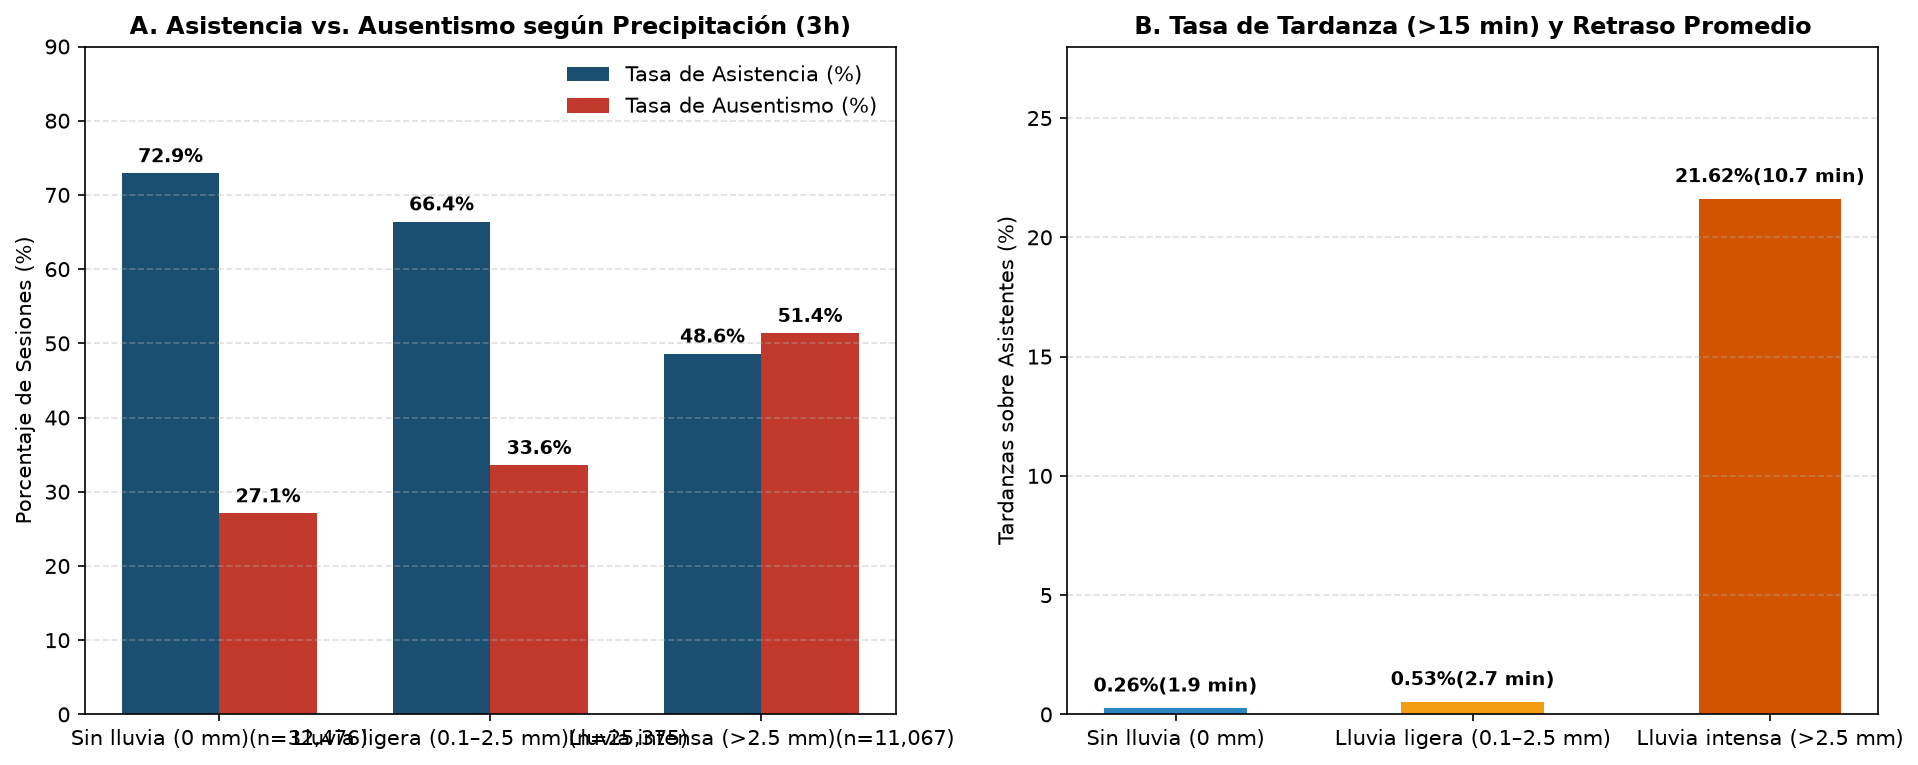

In [55]:
w_sum = df_gold.groupby("condicion_lluvia", observed=False).agg(
    n=("id_evento", "count"),
    att=("asistio_bin", lambda s: s.mean() * 100),
    abs_r=("asistio_bin", lambda s: (1 - s.mean()) * 100),
    tard=("tarde_bin", lambda s: s.sum() / max(1, (df_gold.loc[s.index, "asistio_bin"] == 1).sum()) * 100),
    delay=("retraso_minutos", "mean"),
)
print(w_sum.round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), dpi=150)
cats = ["Sin lluvia (0 mm)", "Lluvia ligera (0.1–2.5 mm)", "Lluvia intensa (>2.5 mm)"]
x = np.arange(len(cats))
w = 0.36
b1 = ax1.bar(x - w / 2, w_sum["att"], width=w, color="#1B4F72", label="Tasa de Asistencia (%)")
b2 = ax1.bar(x + w / 2, w_sum["abs_r"], width=w, color="#C0392B", label="Tasa de Ausentismo (%)")
ax1.set_title("A. Asistencia vs. Ausentismo según Precipitación (3h)", fontsize=11.5, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels([f"{c}(n={n:,})" for c, n in zip(cats, w_sum["n"])])
ax1.set_ylabel("Porcentaje de Sesiones (%)")
ax1.set_ylim(0, 90)
ax1.grid(axis="y", linestyle="--", alpha=0.4)
ax1.legend(frameon=False)
for bar in list(b1) + list(b2):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5, f"{bar.get_height():.1f}%", ha="center", fontsize=9, fontweight="bold")

b3 = ax2.bar(x, w_sum["tard"], width=0.48, color=["#2E86C1", "#F39C12", "#D35400"])
ax2.set_title("B. Tasa de Tardanza (>15 min) y Retraso Promedio", fontsize=11.5, fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels(cats)
ax2.set_ylabel("Tardanzas sobre Asistentes (%)")
ax2.set_ylim(0, 28)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
for bar, dly in zip(b3, w_sum["delay"]):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.7, f"{bar.get_height():.2f}%({dly:.1f} min)", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig1_clima_asistencia_tardanza.png", dpi=220)
plt.show()

### 4.2 Correlación entre asistencia presencial y rendimiento académico (Figura 2)

                    n  nota_prom  aprob  cancel
rango_asistencia                               
Crítica (≤50%)    445       0.03   0.00   96.63
Baja (50–75%)     834       0.67  12.47   59.47
Media (75–85%)    360       2.80  65.28    3.89
Alta (>85%)       388       3.42  87.89    0.52
Correlación Pearson: r = 0.7984 (p = 0.00e+00)
Correlación Spearman: rho = 0.8098 (p = 0.00e+00)


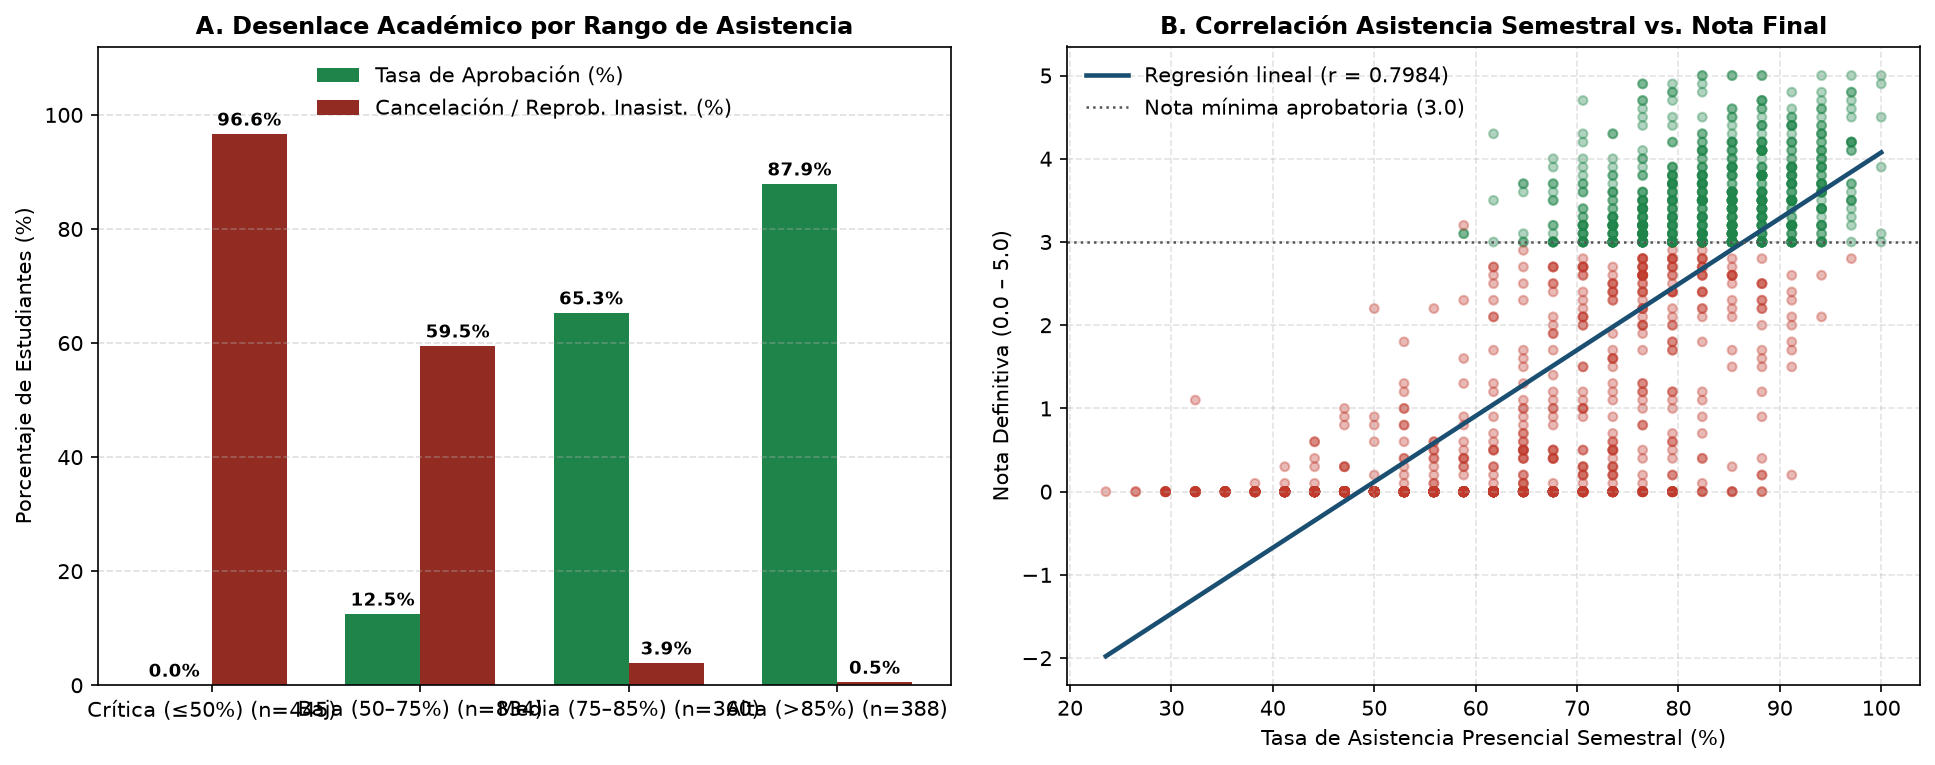

In [56]:
df_student_sem["rango_asistencia"] = pd.cut(
    df_student_sem["tasa_asistencia_pct"],
    bins=[-0.1, 50, 75, 85, 100.1],
    labels=["Crítica (≤50%)", "Baja (50–75%)", "Media (75–85%)", "Alta (>85%)"],
)

b_sum = df_student_sem.groupby("rango_asistencia", observed=False).agg(
    n=("id_estudiante", "count"),
    nota_prom=("Final", "mean"),
    aprob=("aprobo", lambda s: s.mean() * 100),
    cancel=("deserto_o_cancelo", lambda s: s.mean() * 100),
)
print(b_sum.round(2))

r_val, p_pearson = stats.pearsonr(df_student_sem["tasa_asistencia_pct"], df_student_sem["Final"])
rho_val, p_spearman = stats.spearmanr(df_student_sem["tasa_asistencia_pct"], df_student_sem["Final"])
print(f"Correlación Pearson: r = {r_val:.4f} (p = {p_pearson:.2e})")
print(f"Correlación Spearman: rho = {rho_val:.4f} (p = {p_spearman:.2e})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), dpi=150)
x2 = np.arange(len(b_sum))
b1 = ax1.bar(x2 - w / 2, b_sum["aprob"], width=w, color="#1E8449", label="Tasa de Aprobación (%)")
b2 = ax1.bar(x2 + w / 2, b_sum["cancel"], width=w, color="#922B21", label="Cancelación / Reprob. Inasist. (%)")
ax1.set_title("A. Desenlace Académico por Rango de Asistencia", fontsize=11.5, fontweight="bold")
ax1.set_xticks(x2)
ax1.set_xticklabels([f"{idx} (n={n})" for idx, n in zip(["Crítica (≤50%)", "Baja (50–75%)", "Media (75–85%)", "Alta (>85%)"], b_sum["n"])])
ax1.set_ylabel("Porcentaje de Estudiantes (%)")
ax1.set_ylim(0, 112)
ax1.grid(axis="y", linestyle="--", alpha=0.4)
ax1.legend(frameon=False, loc="upper center")
for bar in list(b1) + list(b2):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5, f"{bar.get_height():.1f}%", ha="center", fontsize=8.8, fontweight="bold")

colors_pts = np.where(df_student_sem["aprobo"] == 1, "#1E8449", "#C0392B")
ax2.scatter(df_student_sem["tasa_asistencia_pct"], df_student_sem["Final"], c=colors_pts, alpha=0.35, s=18)
m, b_int = np.polyfit(df_student_sem["tasa_asistencia_pct"], df_student_sem["Final"], 1)
xl = np.linspace(df_student_sem["tasa_asistencia_pct"].min(), 100, 100)
ax2.plot(xl, m * xl + b_int, color="#1B4F72", linewidth=2.2, label=f"Regresión lineal (r = {r_val:.4f})")
ax2.axhline(3.0, color="#555555", linestyle=":", linewidth=1.2, label="Nota mínima aprobatoria (3.0)")
ax2.set_title("B. Correlación Asistencia Semestral vs. Nota Final", fontsize=11.5, fontweight="bold")
ax2.set_xlabel("Tasa de Asistencia Presencial Semestral (%)")
ax2.set_ylabel("Nota Definitiva (0.0 – 5.0)")
ax2.grid(True, linestyle="--", alpha=0.35)
ax2.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig2_asistencia_rendimiento_calculo.png", dpi=220)
plt.show()

### 4.3 Focalización territorial por sede y periodo (Figura 3)

             matriculas  asistencia_prom  nota_media  tasa_aprobacion
campus                                                               
ROBLEDO             455            65.16        1.28            28.35
FRATERNIDAD        1437            66.99        1.47            34.66
CASTILLA             82            67.25        1.57            39.02
CAMPUS C4TA          53            68.04        1.62            39.62


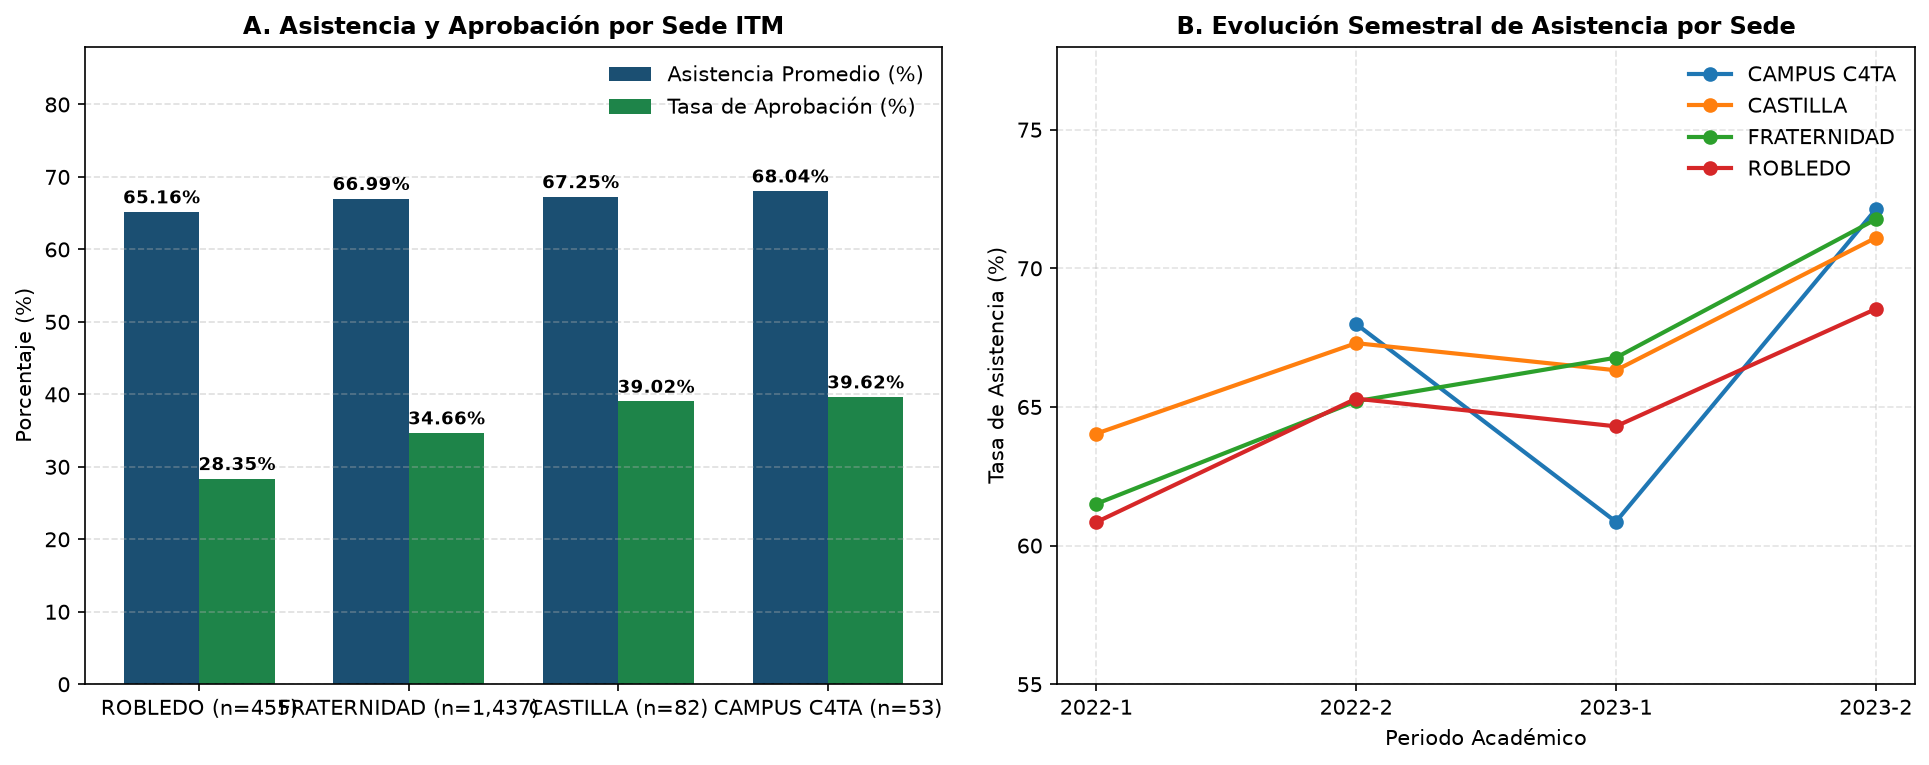

In [57]:
sede_sum = df_student_sem.groupby("campus").agg(
    matriculas=("id_estudiante", "count"),
    asistencia_prom=("tasa_asistencia_pct", "mean"),
    nota_media=("Final", "mean"),
    tasa_aprobacion=("aprobo", lambda s: s.mean() * 100),
).sort_values("asistencia_prom")
print(sede_sum.round(2))

piv_per = df_student_sem.pivot_table(
    index="periodo", columns="campus", values="tasa_asistencia_pct", aggfunc="mean"
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), dpi=150)
x3 = np.arange(len(sede_sum))
b1 = ax1.bar(x3 - w / 2, sede_sum["asistencia_prom"], width=w, color="#1B4F72", label="Asistencia Promedio (%)")
b2 = ax1.bar(x3 + w / 2, sede_sum["tasa_aprobacion"], width=w, color="#1E8449", label="Tasa de Aprobación (%)")
ax1.set_title("A. Asistencia y Aprobación por Sede ITM", fontsize=11.5, fontweight="bold")
ax1.set_xticks(x3)
ax1.set_xticklabels([f"{c} (n={n:,})" for c, n in zip(sede_sum.index, sede_sum["matriculas"])])
ax1.set_ylabel("Porcentaje (%)")
ax1.set_ylim(0, 88)
ax1.grid(axis="y", linestyle="--", alpha=0.4)
ax1.legend(frameon=False)
for bar in list(b1) + list(b2):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.2, f"{bar.get_height():.2f}%", ha="center", fontsize=8.5, fontweight="bold")

for col in piv_per.columns:
    ax2.plot(piv_per.index, piv_per[col], marker="o", linewidth=2, label=col)
ax2.set_title("B. Evolución Semestral de Asistencia por Sede", fontsize=11.5, fontweight="bold")
ax2.set_xlabel("Periodo Académico")
ax2.set_ylabel("Tasa de Asistencia (%)")
ax2.set_ylim(55, 78)
ax2.grid(True, linestyle="--", alpha=0.35)
ax2.legend(frameon=False)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig3_comparativo_sedes_periodos.png", dpi=220)
plt.show()